In [6]:
import pandas as pd
df = pd.read_csv("shap_summary_all_coins.csv")

# drop leakage variable
df = df[df["feature"] != "ret_1w_original"]

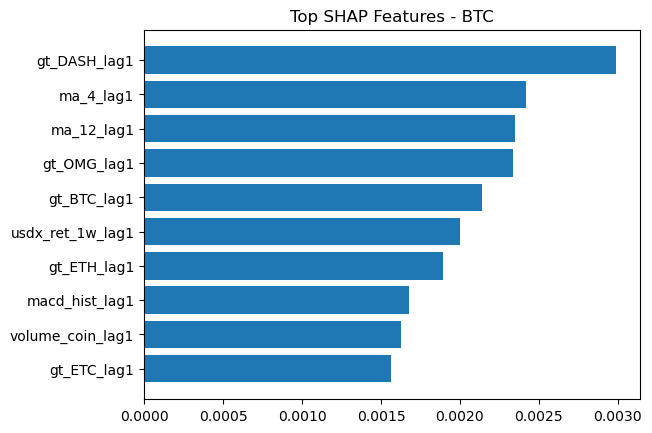

In [7]:
# BTC plot 
import matplotlib.pyplot as plt

df_btc = df[df["coin"] == "BTC"].sort_values("mean_abs_shap", ascending=False).head(10)

plt.figure()
plt.barh(df_btc["feature"], df_btc["mean_abs_shap"])
plt.gca().invert_yaxis()
plt.title("Top SHAP Features - BTC")
plt.show()

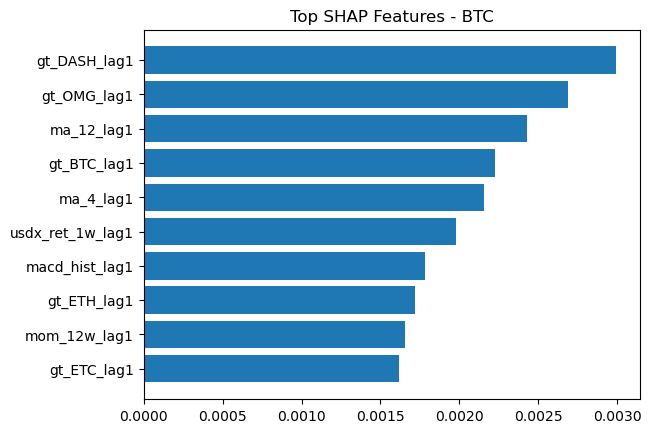

In [8]:
# eth plot 

import matplotlib.pyplot as plt

df_btc = df[df["coin"] == "ETH"].sort_values("mean_abs_shap", ascending=False).head(10)

plt.figure()
plt.barh(df_btc["feature"], df_btc["mean_abs_shap"])
plt.gca().invert_yaxis()
plt.title("Top SHAP Features - BTC")
plt.show()

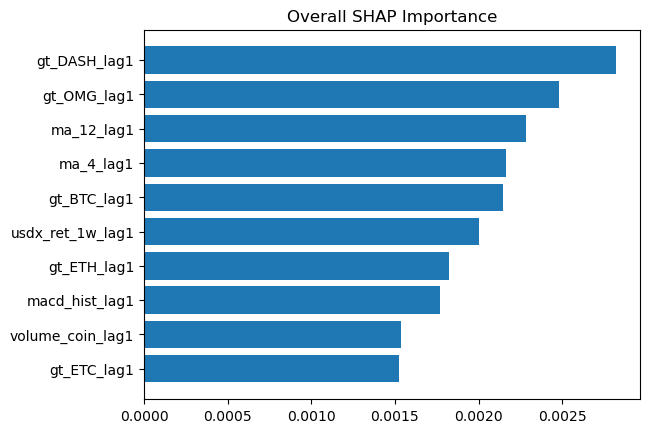

In [9]:
# average across all coins 

df_all = (
    df.groupby("feature")["mean_abs_shap"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure()
plt.barh(df_all.index, df_all.values)
plt.gca().invert_yaxis()
plt.title("Overall SHAP Importance")
plt.show()

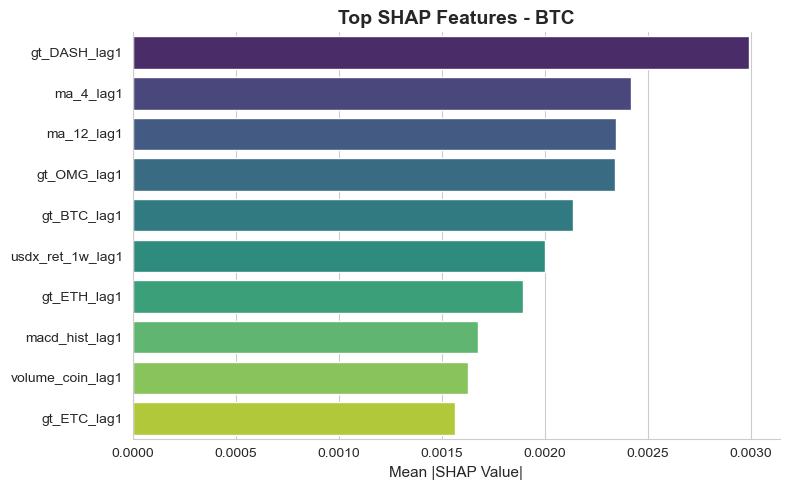

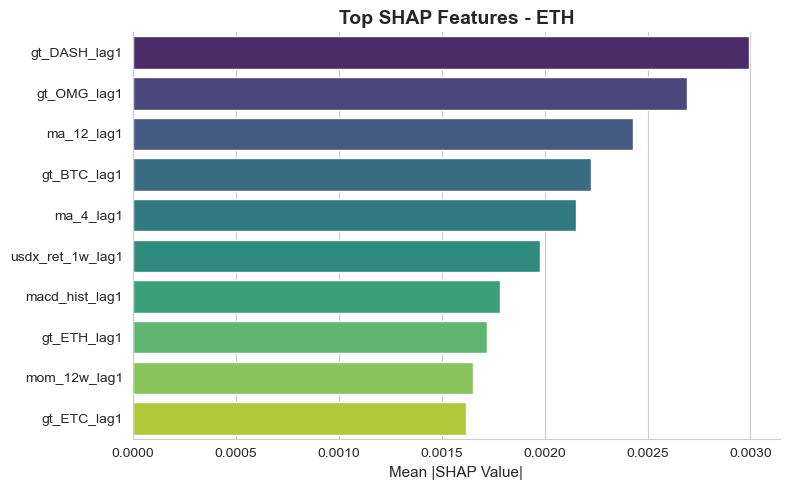

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# set style
sns.set_style("whitegrid")

def plot_shap(df, coin, top_n=10):
    df_coin = (
        df[df["coin"] == coin]
        .sort_values("mean_abs_shap", ascending=False)
        .head(top_n)
    )
    
    plt.figure(figsize=(8, 5))
    
    sns.barplot(
        x="mean_abs_shap",
        y="feature",
        data=df_coin,
        palette="viridis"
    )
    
    plt.title(f"Top SHAP Features - {coin}", fontsize=14, weight="bold")
    plt.xlabel("Mean |SHAP Value|", fontsize=11)
    plt.ylabel("")
    
    sns.despine()
    plt.tight_layout()
    plt.show()
    
plot_shap(df, "BTC")
plot_shap(df, "ETH")

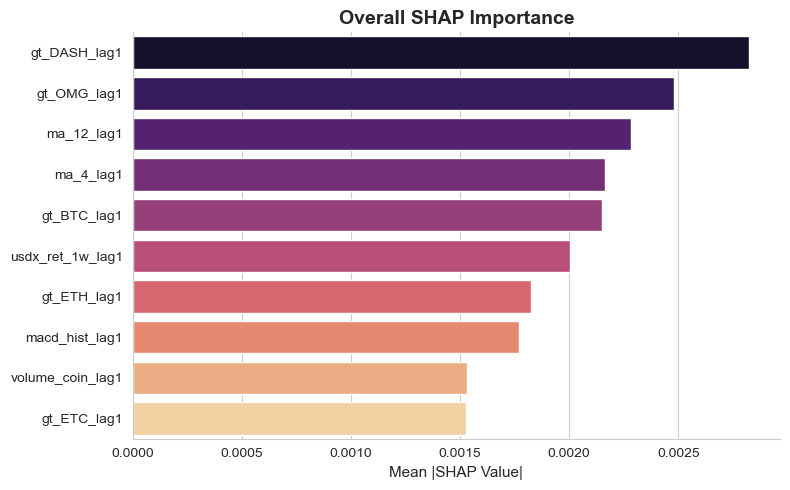

In [13]:
def plot_overall_shap(df, top_n=10):
    df_all = (
        df.groupby("feature")["mean_abs_shap"]
        .mean()
        .sort_values(ascending=False)
        .head(top_n)
        .reset_index()
    )
    
    plt.figure(figsize=(8, 5))
    
    sns.barplot(
        x="mean_abs_shap",
        y="feature",
        data=df_all,
        palette="magma"
    )
    
    plt.title("Overall SHAP Importance", fontsize=14, weight="bold")
    plt.xlabel("Mean |SHAP Value|", fontsize=11)
    plt.ylabel("")
    
    sns.despine()
    plt.tight_layout()
    plt.show()

plot_overall_shap(df)